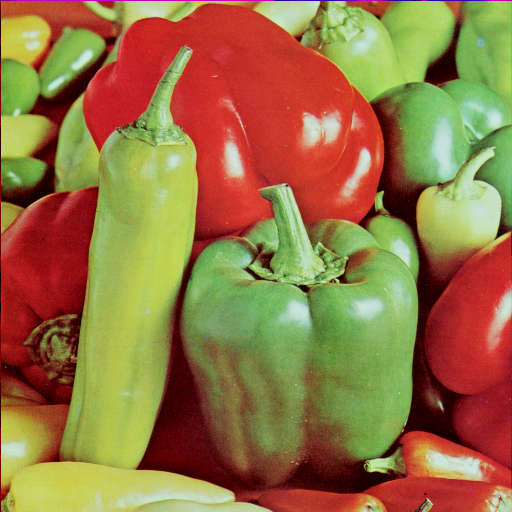

In [ ]:
import sys

sys.path.append('../src')

from PIL import Image, ImageFont

from palette.symbol2value import PALETTES, stream_width_aligned_permutations
from image.processing import preprocess_img
from converters.img_converter import ImgConverter
from converters.line_heuristics.harmony_search import HarmonyLineSearch
from converters.tile.nearest import Tile2SymbNearest
from rendering.image import render_symbols_img

FONT_SIZE = 10
MONO_FONT = ImageFont.truetype("../fonts/FiraCode-Regular.ttf", FONT_SIZE)
NON_MONO_FONT = ImageFont.truetype("../fonts/OpenSans-Regular.ttf", FONT_SIZE)

MONO_SYMBOLS = PALETTES['asciis']
NON_MONO_SYMBOLS = list(stream_width_aligned_permutations(MONO_SYMBOLS, NON_MONO_FONT))

IMG_PATH = "../imgs/peppers.tiff"
orig_img = Image.open(IMG_PATH).convert("RGB")
display(orig_img)

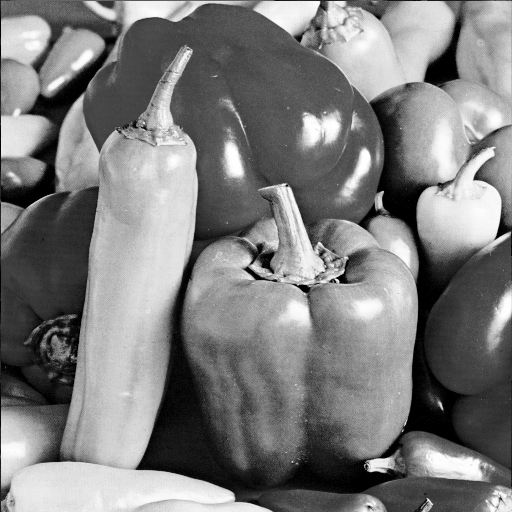

In [16]:
prep_img = preprocess_img(orig_img, grayscale=True, contrast=1.5)
prep_img

d:\CS Projects\python-playground\python-ascii-art\notebooks\../src\converters\tile\nearest.py:40: UserWarning: It is recommended to use mode = grid-constant instead of constant when grid_mode is True.
  tile = zoom(tile, zoom_factors, order=0, grid_mode=True)


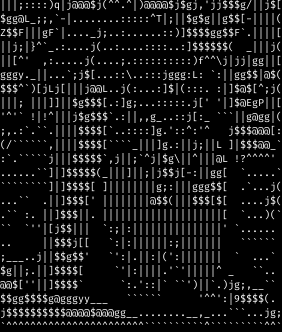

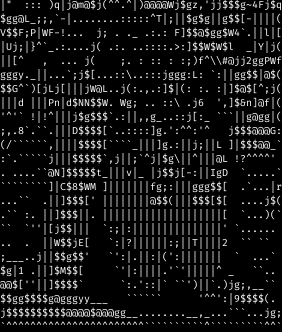

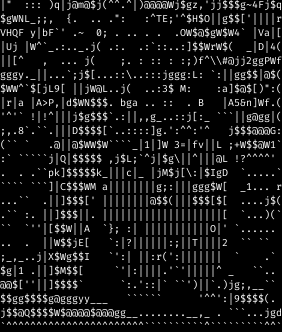

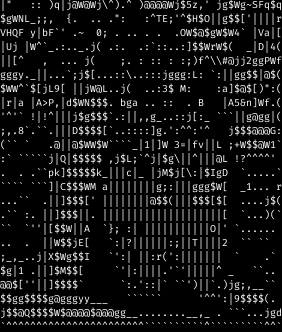

In [3]:
tile_converter = Tile2SymbNearest(symbols=MONO_SYMBOLS, font=MONO_FONT)
converter = HarmonyLineSearch(symbols=MONO_SYMBOLS,
                              font=MONO_FONT,
                              pop_count=5,
                              generations=80,
                              tile_converter=tile_converter)

img_converter_gen = ImgConverter(converter, MONO_FONT).img2symbols_lazy(prep_img,
                                              max_cols=80,
                                              max_lines=24,
                                              gens_per_step=40)
last_res = None
for res_arr in img_converter_gen:
    last_res = res_arr
    display(render_symbols_img(last_res, MONO_FONT))

In [18]:
from rendering.ansi_colorizer import AnsiColorizer, colorize_symbols

res_colorized = colorize_symbols(orig_img,
                                 last_res,
                                 MONO_FONT,
                                 AnsiColorizer(fg_brightness_scale=1.0,
                                               bg_brightness_scale=0.1,
                                               use_ansi_256_colors=False))
print('\n'.join(''.join(s) for s in res_colorized))

|"   :: )q|j@W@Wj\^).^ )@@@@Wj$5z,' jg$Wg~SFq$q
$gWNL_;;,  {.  .. .":   :^TE;'^$H$O||g$$['||||r
VHQF y|bF`' .~  0; . .. . .  .OW$@$gW$W4` |Va|[
|Uj |W^`_.:.._.j( .:.  .:`::..:]$$WrW$(  _|D|4(
||[^   ,  ... j(    ;. : :: : :;)f^\\#@jj2ggPWf
gggy._||...`;j$[...::\..:::jggg:L: `:||gg$$|@$(
$WW^`$[jL9[ ||jW@L..j(  ..:3$ M:    :a]$@$[)":(
|r|a |A>P,|d$WN$$$. bga .. ::  . B   |A5&n]Wf.(
'^'` !|!^|||j$g$$$`.:||,,g_..::j[:_ ```||g@gg|(
;,.8`.``.|||D$$$$[`..::::]g.':^^:'^   j$$$@@@G:
(`` `   .@||@$WW$W````_|1|]W 3=|fv||L ;+W$$@W1`
:` `````j|Q|$$$$$ ,j$L;`^j|$g\||^|||@L !?^^^^' 
.  . .``pk]$$$$$k_|||c|_ |jM$j[\:|$IgD  `.....`
```` ```]|C$$$WM a||||||||g;:|||ggg$W[  _1... r
...``  .||]$$$[' ||||||||@$$(|||$$$[$[  ....j$(
.`` :. ||]$$$||. ||||||||||||||||||||[  `...)(`
``  `''|[$$W||A  `}; :| |||||||||||O|' `...... 
..  .  ||W$$jE[   `:|?||||||:;||T||||2  `` ``  
;_,_..j|X$Wg$$I   `':| ||:r(':|||||||  `    .` 
$g|1 .||]$M$$[     `'|:||||.'`'|||||^ _   ``.. 
@@$[''||]$$$$`      `:.'::|` ``')||`.)jg

d:\CS Projects\python-playground\python-ascii-art\notebooks\../src\converters\tile\nearest.py:40: UserWarning: It is recommended to use mode = grid-constant instead of constant when grid_mode is True.
  tile = zoom(tile, zoom_factors, order=0, grid_mode=True)


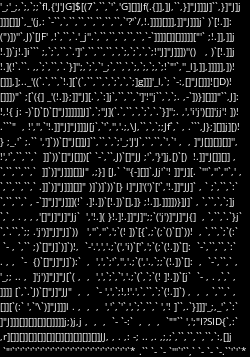

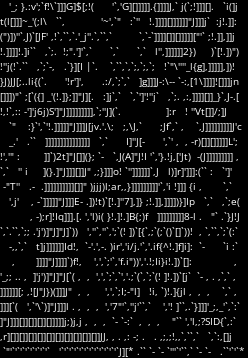

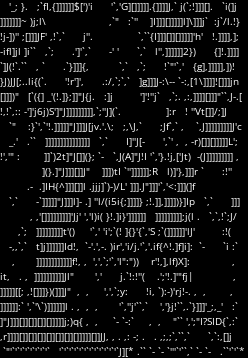

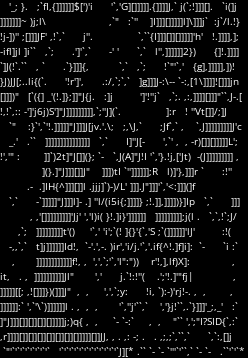

In [8]:
tile_converter = Tile2SymbNearest(symbols=NON_MONO_SYMBOLS[::10], font=NON_MONO_FONT, val_wh=(6, 6))
converter = HarmonyLineSearch(symbols=NON_MONO_SYMBOLS,
                              font=NON_MONO_FONT,
                              pop_count=5,
                              generations=80,
                              tile_converter=tile_converter)

img_converter_gen = ImgConverter(converter, NON_MONO_FONT).img2symbols_lazy(prep_img,
                                              max_cols=80,
                                              max_lines=24,
                                              gens_per_step=40)
for res_arr in img_converter_gen:
    display(render_symbols_img(res_arr, NON_MONO_FONT))